In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Import Data

In [18]:
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces()
print(data)

{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], dtype=float32), 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
         0.3305785 , 0.30578512],
        [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
         0.338843  , 0.3140496 ],
        [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
         0.338843  , 0.29752067],
        ...,
        [0.21487603, 0.20661157, 0.2231405 , ..., 0.15289256,
         0.16528925, 0.17

# dataset features

In [19]:
print(f'feature dimention: {data['images'].shape}')
print(f'target dimention: {data['target'].shape}')
print(f'number of classes: {len(np.unique(data['target']))}')

feature dimention: (400, 64, 64)
target dimention: (400,)
number of classes: 40


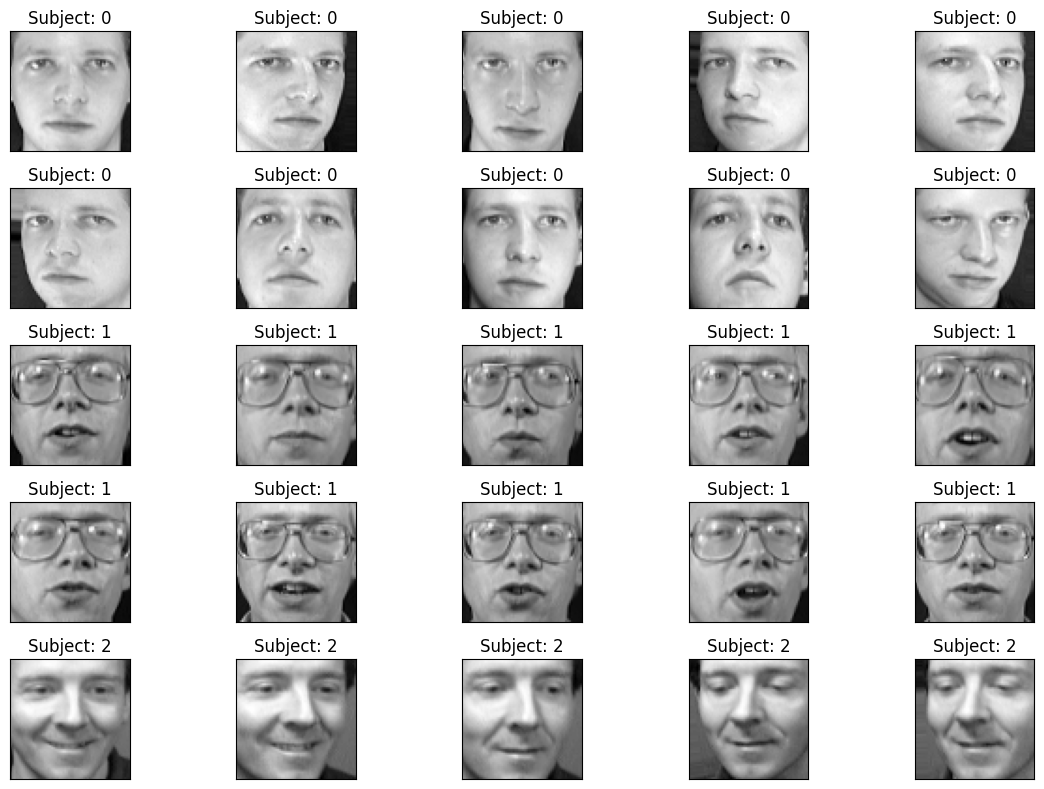

In [20]:
n_row, n_col = 5, 5
fig, ax = plt.subplots(n_row, n_col, figsize=(12, 8))
ax = ax.flatten()

for i in range(n_row * n_col):
    ax[i].imshow(data.images[i], cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_title(f'Subject: {data.target[i]}')

plt.tight_layout()
plt.show()

# Dataset split

In [21]:
from sklearn.model_selection import train_test_split

X, y = data['images'], data['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.66, random_state=42, stratify=y_test)

In [22]:
# check split
from collections import Counter

def check_assertion(y, expected_val, message):
    for val in Counter([yv for yv in y]).values():
        assert val == expected_val, message
    print('assertion passed')

check_assertion(y_train, 7, 'train split is not correct')
check_assertion(y_val, 1, 'val split is not correct')
check_assertion(y_test, 2, 'test split is not correct')

assertion passed
assertion passed
assertion passed


# Flatten

In [23]:
def flatten_images(images:np.ndarray) -> np.ndarray:
    return images.reshape(images.shape[0], -1)

X_train_flatten = flatten_images(X_train)
X_val_flatten = flatten_images(X_val)
X_test_flatten = flatten_images(X_test)

print(f'train shape: {X_train_flatten.shape}')
print(f'val shape: {X_val_flatten.shape}')
print(f'test shape: {X_test_flatten.shape}')

train shape: (280, 4096)
val shape: (40, 4096)
test shape: (80, 4096)


# mean images

In [24]:
train_mean = np.mean(X_train_flatten, axis=0)
test_mean = np.mean(X_test_flatten, axis=0)
val_mean = np.mean(X_val_flatten, axis=0)

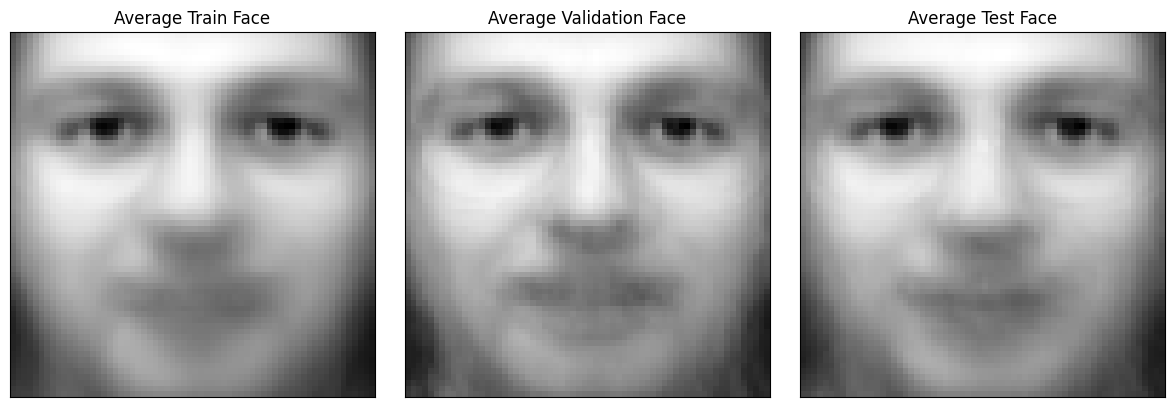

In [25]:
# showing average faces
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(train_mean.reshape(64, 64), cmap='gray')
ax[0].set_title('Average Train Face')
ax[0].set_xticks([])
ax[0].set_yticks([])

ax[1].imshow(val_mean.reshape(64, 64), cmap='gray')
ax[1].set_title('Average Validation Face')
ax[1].set_xticks([])
ax[1].set_yticks([])

ax[2].imshow(test_mean.reshape(64, 64), cmap='gray')
ax[2].set_title('Average Test Face')
ax[2].set_xticks([])
ax[2].set_yticks([])

plt.tight_layout()
plt.show()

# PCA from scratch

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 279]
accuracy = dict()

X_train_centered = X_train_flatten - train_mean
X_val_centered = X_val_flatten - train_mean
X_test_centered = X_test_flatten - train_mean

X_train_eigenvalues, X_train_eigenvectors = np.linalg.eigh(np.cov(X_train_centered.T))
sorted_indices_train = np.argsort(X_train_eigenvalues)[::-1]
sorted_eigenvectors_train = X_train_eigenvectors[:, sorted_indices_train]

for k in k_values:
    X_train_projected = X_train_centered @ sorted_eigenvectors_train[:, :k]
    X_val_projected = X_val_centered @ sorted_eigenvectors_train[:, :k]
    classifier = KNeighborsClassifier(n_neighbors=1)
    classifier.fit(X_train_projected, y_train)
    y_pred = classifier.predict(X_val_projected)
    accuracy[k] = accuracy_score(y_val, y_pred)
    print(f'k: {k}, accuracy: {accuracy[k]}')


k: 5, accuracy: 0.75
k: 10, accuracy: 0.875
k: 15, accuracy: 0.875
k: 20, accuracy: 0.875
k: 25, accuracy: 0.875
k: 30, accuracy: 0.875
k: 40, accuracy: 0.875
k: 50, accuracy: 0.875
k: 75, accuracy: 0.875
k: 100, accuracy: 0.875
k: 150, accuracy: 0.875
k: 200, accuracy: 0.875
k: 279, accuracy: 0.875


# accuracy as function of k

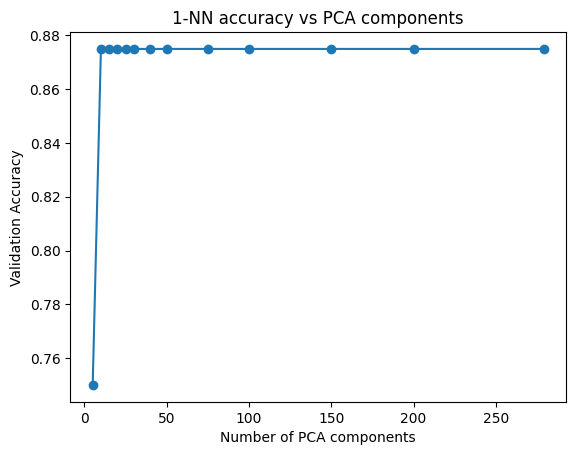

In [27]:
plt.plot(list(accuracy.keys()), list(accuracy.values()), marker='o')
plt.xlabel('Number of PCA components')
plt.ylabel('Validation Accuracy')
plt.title('1-NN accuracy vs PCA components')
plt.show()

# picking optimal k

In [28]:
best_k = 0
for k in accuracy:
    if accuracy[k] == max(accuracy.values()):
        best_k = k
        break
print(f'optimal k: {best_k}')


optimal k: 10


# visualize eigenface

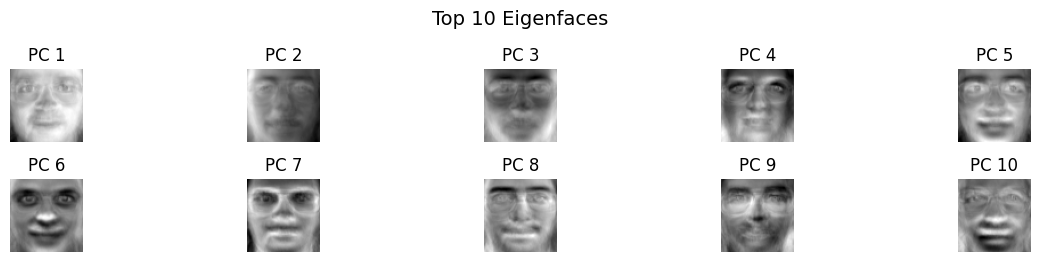

In [29]:
import matplotlib.pyplot as plt

h, w = 64, 64

eigenfaces = sorted_eigenvectors_train[:, :best_k].T

plt.figure(figsize=(12, 6))
for i in range(best_k):
    plt.subplot(5, 5, i + 1)
    face = eigenfaces[i].reshape((h, w))
    face_min, face_max = face.min(), face.max()
    face = (face - face_min) / (face_max - face_min)
    plt.imshow(face, cmap='gray')
    plt.axis('off')
    plt.title(f'PC {i+1}')
plt.suptitle(f'Top {best_k} Eigenfaces', fontsize=14)
plt.tight_layout()
plt.show()


# test set performance

In [30]:
clf = KNeighborsClassifier(n_neighbors=1)
X_train_projected = X_train_centered @ sorted_eigenvectors_train[:, :best_k]
X_test_projected = X_test_centered @ sorted_eigenvectors_train[:, :best_k]
clf.fit(X_train_projected, y_train)
y_pred = clf.predict(X_test_projected)
test_accuracy = accuracy_score(y_test, y_pred)
print(f'accuracy: {test_accuracy}')

accuracy: 0.925


# comparision with scikit learn

In [31]:
from sklearn.decomposition import PCA

sk_accuracy = dict()
for k in k_values:
    pca = PCA(n_components=k)
    X_train_pca = pca.fit_transform(X_train_flatten)
    X_val_pca = pca.transform(X_val_flatten)
    classifier = KNeighborsClassifier(n_neighbors=1)
    classifier.fit(X_train_pca, y_train)
    y_pred = classifier.predict(X_val_pca)
    sk_accuracy[k] = accuracy_score(y_val, y_pred)
    print(f'k: {k}, accuracy: {sk_accuracy[k]}')

# optimal
sk_best_k = 0
for k in sk_accuracy:
    if sk_accuracy[k] == max(sk_accuracy.values()):
        sk_best_k = k
        break
print(f'optimal k: {sk_best_k}')

# test set performance
pca = PCA(n_components=sk_best_k)
X_train_pca = pca.fit_transform(X_train_flatten)
X_test_pca = pca.transform(X_test_flatten)
classifier = KNeighborsClassifier(n_neighbors=1)
classifier.fit(X_train_pca, y_train)
y_pred = classifier.predict(X_test_pca)
sk_test_accuracy = accuracy_score(y_test, y_pred)
print(f'optimal k: test accuracy {sk_test_accuracy}')

k: 5, accuracy: 0.75
k: 10, accuracy: 0.875
k: 15, accuracy: 0.875
k: 20, accuracy: 0.875
k: 25, accuracy: 0.875
k: 30, accuracy: 0.875
k: 40, accuracy: 0.875
k: 50, accuracy: 0.875
k: 75, accuracy: 0.875
k: 100, accuracy: 0.875
k: 150, accuracy: 0.875
k: 200, accuracy: 0.875
k: 279, accuracy: 0.875
optimal k: 10
optimal k: test accuracy 0.925


# comparision

In [32]:
print(f'my impl best k: {best_k}')
print(f'my impl accuracy: {test_accuracy}')
print(f'sklearn best k: {sk_best_k}')
print(f'sklearn accuracy: {sk_test_accuracy}')

for k in k_values:
    assert accuracy[k] == sk_accuracy[k], f'k: {k}, my impl accuracy: {accuracy[k]}, sklearn accuracy: {sk_accuracy[k]}'
print('assertion passed')

my impl best k: 10
my impl accuracy: 0.925
sklearn best k: 10
sklearn accuracy: 0.925
assertion passed
